# Global Unemployment and Economic Trend Analysis

## Project Overview

This project analyzes GDP growth, total unemployment, and youth unemployment across 24 countries using World Bank data. It compares developed and developing countries, examines trends during the 2008 financial crisis and COVID-19 pandemic, and explores the relationship between economic growth and unemployment using Python, statistical analysis, and visualizations.

## Research Questions
1. How did GDP growth and unemployment change over the study period?
2. How does youth unemployment compare with total unemployment?
3. How do the selected developed and developing country groups differ?
4. How did GDP growth and unemployment indicators change around 2009 and 2020?
5. Were year-over-year changes in youth unemployment larger than changes in total unemployment in those years?
6. How are GDP growth and unemployment indicators associated?

## Dataset
- **Source:** World Bank, World Development Indicators
- **Coverage:** **24** selected countries ['Australia', 'Bangladesh', 'Brazil', 'Canada', 'China', 'Egypt',
       'France', 'Germany', 'Greece', 'India', 'Indonesia', 'Italy',
       'Japan', 'Mexico', 'Philippines', 'Poland', 'South Africa',
       'South Korea', 'Spain', 'Sweden', 'Turkey', 'United Kingdom',
       'United States', 'Vietnam']**, 2000–2025**
- **Indicators:** annual GDP growth, total unemployment rate, and youth unemployment rate (ages 15–24)
- **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1. Data Preparation
1. Loaded the dataset and treated `..` as missing values.
2. Renamed columns for readability.
3. Standardized country names.
4. Checked shape, data types, duplicates and missing values.
5. Saved the cleaned dataset.

In [31]:
# 1. Load the data 
df = pd.read_excel("P_Data_Extract_From_World_Development_Indicators (1).xlsx", na_values="..")
df.head()

,Time,Time Code,Country Name,Country Code,GDP growth (annual %) [NY.GDP.MKTP.KD.ZG],"Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]","Unemployment, youth total (% of total labor force ages 15-24) (modeled ILO estimate) [SL.UEM.1524.ZS]"
0,2000,YR2000,Australia,AUS,3.916057,6.288,12.084
1,2000,YR2000,Bangladesh,BGD,5.293295,3.270,9.744
2,2000,YR2000,Brazil,BRA,4.387949,10.889,20.327
3,2000,YR2000,Canada,CAN,5.138539,6.829,12.669
4,2000,YR2000,China,CHN,8.573573,3.260,6.840


In [32]:
# 2. Rename columns and drop the column we don't need
df = df.rename(columns={
    "Time": "Year",
    "Country Name": "Country",
    "Country Code": "Code",
    "GDP growth (annual %) [NY.GDP.MKTP.KD.ZG]": "GDP_Growth",
    "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]": "Unemployment_Total",
    "Unemployment, youth total (% of total labor force ages 15-24) (modeled ILO estimate) [SL.UEM.1524.ZS]": "Youth_Unemployment",
})
df = df.drop(columns=["Time Code"])

In [33]:
# Standardize country labels used in the source file
df["Country"] = df["Country"].replace({
    "Korea, Rep.": "South Korea",
    "Egypt, Arab Rep.": "Egypt",
    "Turkiye": "Turkey",
    "Viet Nam": "Vietnam",
})

# convert Year to numeric before sorting
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df = df.sort_values(["Country", "Year"]).reset_index(drop=True)

In [34]:
df['Country'].unique()

array(['Australia', 'Bangladesh', 'Brazil', 'Canada', 'China', 'Egypt',
       'France', 'Germany', 'Greece', 'India', 'Indonesia', 'Italy',
       'Japan', 'Mexico', 'Philippines', 'Poland', 'South Africa',
       'South Korea', 'Spain', 'Sweden', 'Turkey', 'United Kingdom',
       'United States', 'Vietnam'], dtype=object)

In [35]:
# 4. Basic checks
print("Shape:", df.shape)
print("Countries:", df["Country"].nunique())
print("Years:", df["Year"].min(), "to", df["Year"].max())
print("Duplicate country-year rows:", df.duplicated(["Country", "Year"]).sum())
print()
print("Missing values:")
print(df.isnull().sum())
print()
df.info()

Shape: (624, 6)
Countries: 24
Years: 2000 to 2025
Duplicate country-year rows: 0

Missing values:
Year                  0
Country               0
Code                  0
GDP_Growth            0
Unemployment_Total    0
Youth_Unemployment    0
dtype: int64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 624 entries, 0 to 623
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Year                624 non-null    int64  
 1   Country             624 non-null    object 
 2   Code                624 non-null    object 
 3   GDP_Growth          624 non-null    float64
 4   Unemployment_Total  624 non-null    float64
 5   Youth_Unemployment  624 non-null    float64
dtypes: float64(3), int64(1), object(2)
memory usage: 29.4+ KB


In [36]:
# save the cleaned file
df.to_csv("cleaned_data.csv", index=False)

## 2. Feature Engineering

Created a small set of variables used in the analysis:

- `Group`: Developed or Developing, project-defined country grouping.
- `Youth_Ratio`: youth unemployment rate divided by total unemployment rate.
- `Unemp_Change`: year-over-year change in total unemployment, in percentage points.
- `Youth_Change`: year-over-year change in youth unemployment, in percentage points.
- `GDP_Lag1`: previous year’s GDP growth for the same country.

The change variables are calculated within each country so that values from different countries are not mixed.

In [37]:
# Group: Developed (high-income) or Developing
developed = ["Australia", "Canada", "France", "Germany", "Greece", "Italy", "Japan",
             "Poland", "South Korea", "Spain", "Sweden",
             "United Kingdom", "United States"]

df["Group"] = np.where(df["Country"].isin(developed), "Developed", "Developing")
print(df.groupby("Group")["Country"].nunique())

Group
Developed     13
Developing    11
Name: Country, dtype: int64


In [38]:
# Youth ratio: how many times higher is youth unemployment than total?
df["Youth_Ratio"] = df["Youth_Unemployment"] / df["Unemployment_Total"]

# Change from the previous year, calculated separately for each country
df["Unemp_Change"] = df.groupby("Country")["Unemployment_Total"].diff()
df["Youth_Change"] = df.groupby("Country")["Youth_Unemployment"].diff()

# Previous year's GDP growth, separately for each country
df["GDP_Lag1"] = df.groupby("Country")["GDP_Growth"].shift(1)

df[["Country", "Year","GDP_Growth",  "Unemployment_Total", "Youth_Unemployment", "Youth_Ratio", "Unemp_Change","Youth_Change", "GDP_Lag1"]].head()

,Country,Year,GDP_Growth,Unemployment_Total,Youth_Unemployment,Youth_Ratio,Unemp_Change,Youth_Change,GDP_Lag1
0,Australia,2000,3.916057,6.288,12.084,1.921756,NaN,NaN,NaN
1,Australia,2001,2.031459,6.747,13.476,1.997332,0.459,1.392,3.916057
2,Australia,2002,3.949805,6.375,12.794,2.006902,-0.372,-0.682,2.031459
3,Australia,2003,3.091280,5.933,11.962,2.016181,-0.442,-0.832,3.949805
4,Australia,2004,4.218941,5.399,11.366,2.105205,-0.534,-0.596,3.091280


**Why these variables are used:** The ratio compares the two unemployment rates, while the change variables show whether rates increased or decreased from the previous year. `GDP_Lag1` is created for possible follow-up analysis; it should be removed if it is not used in the final analysis.

## 3. Exploratory Data Analysis

This section describes;
* the distributions of the main indicators
* compares the selected country groups
* identifies extreme country-year observations
* and examines the relationship between total and youth unemployment.

### 3.1 Summary Statistics and Distributions

Use descriptive statistics, histograms, Boxplots to understand the typical values, spread, and shape of GDP growth and unemployment rates.

In [39]:
cols = ["GDP_Growth", "Unemployment_Total", "Youth_Unemployment"]
df[cols].describe().round(2)

,GDP_Growth,Unemployment_Total,Youth_Unemployment
count,624.00,624.00,624.00
mean,3.19,7.77,18.06
std,3.33,5.67,11.84
min,-10.94,1.00,3.23
25%,1.53,4.03,9.42
50%,3.09,6.39,14.66
75%,5.26,9.28,22.96
max,14.15,34.01,65.45


In [40]:
# Does the average differ by group?
df.groupby("Group")[cols + ["Youth_Ratio"]].mean().round(2)

,GDP_Growth,Unemployment_Total,Youth_Unemployment,Youth_Ratio
Group,,,,
Developed,1.89,7.76,18.07,2.34
Developing,4.72,7.79,18.06,2.52


**Summary:** Compare means and medians to see whether extreme values may influence averages. The group-level table helps describe differences in the selected country groups, but group averages alone do not explain why those differences exist.

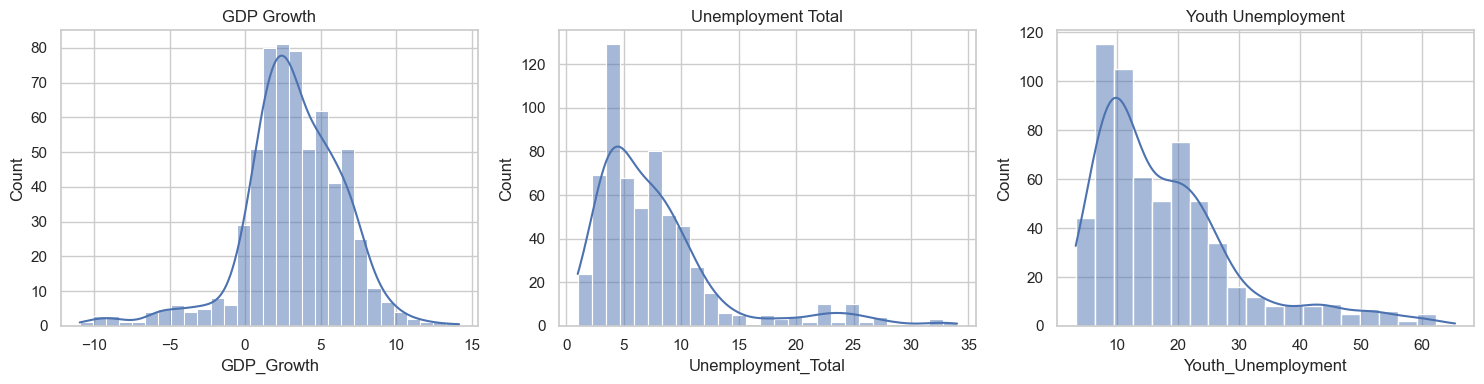

In [41]:
# Distribution of each indicator
plt.figure(figsize=(15, 4))
for i, col in enumerate(cols):
    plt.subplot(1, 3, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(col.replace("_", " "))
plt.tight_layout()
plt.show()

**Interpretation:** GDP growth is bell-shaped, with most values between 0% and 8%. Other two distributions with a long tail toward higher unemployment values is right-skewed. Where extreme values pull the mean away from the median.

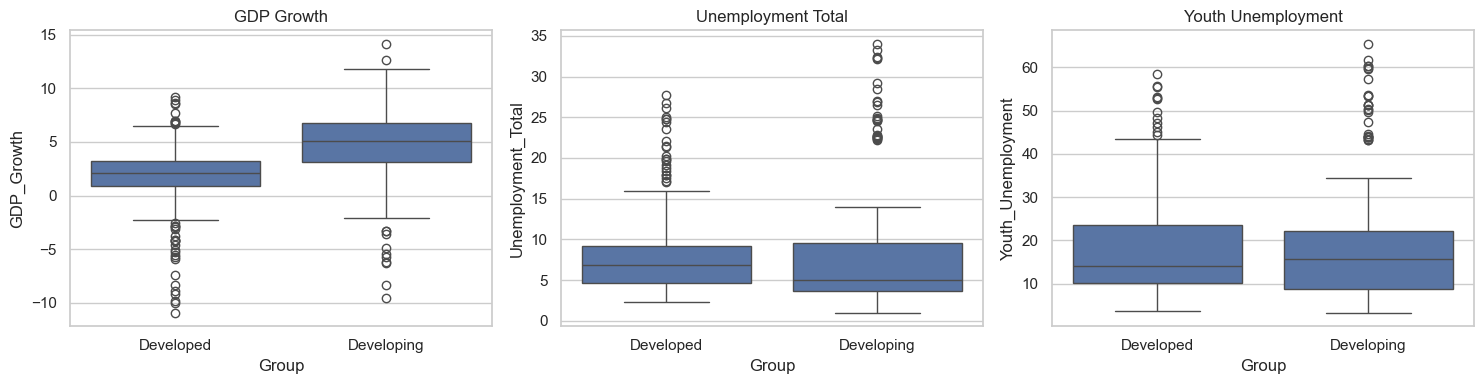

In [42]:
# Boxplots by group
plt.figure(figsize=(15, 4))
for i, col in enumerate(cols):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(data=df, x="Group", y=col)
    plt.title(col.replace("_", " "))
plt.tight_layout()
plt.show()

**Interpretation:** 
* GDP Growth – Developing countries have higher growth and greater variation, with extreme positive and negative outliers.
* Total Unemployment – Both groups have similar average unemployment (about 7.8%). Developed countries have a slightly higher median, while developing countries show more extreme high values.
* Youth Unemployment – Developing countries have a slightly higher median, with substantial variation and high outliers.

In [43]:
# Which country-years are the extremes?
print("Lowest GDP growth:")
print(df.nsmallest(5, "GDP_Growth")[["Country", "Year", "GDP_Growth"]])
print()
print("Highest youth unemployment:")
print(df.nlargest(5, "Youth_Unemployment")[["Country", "Year", "Youth_Unemployment"]])

Lowest GDP growth:
            Country  Year  GDP_Growth
488           Spain  2020  -10.940071
566  United Kingdom  2020  -10.047897
219          Greece  2011   -9.876779
384     Philippines  2020   -9.518295
228          Greece  2020   -9.196231

Highest youth unemployment:
          Country  Year  Youth_Unemployment
437  South Africa  2021              65.451
438  South Africa  2022              61.676
439  South Africa  2023              60.259
440  South Africa  2024              60.248
441  South Africa  2025              59.930


**Interpretation:** **Main Economic Pattern**

- The sharpest GDP contractions occurred mainly in 2020, with Spain and the United Kingdom experiencing the largest declines in the selected data.
- Greece experienced major GDP contractions in both 2011 and 2020, indicating significant economic downturns in separate periods.
- South Africa's youth unemployment remained extremely high from 2021 to 2025, suggesting a persistent challenge in youth employment rather than a single-year spike.

### 3.2 Relationships and Country Comparisons

Examine how total unemployment relates to youth unemployment, compare the youth-to-total unemployment ratio across countries, and inspect average trends over time.

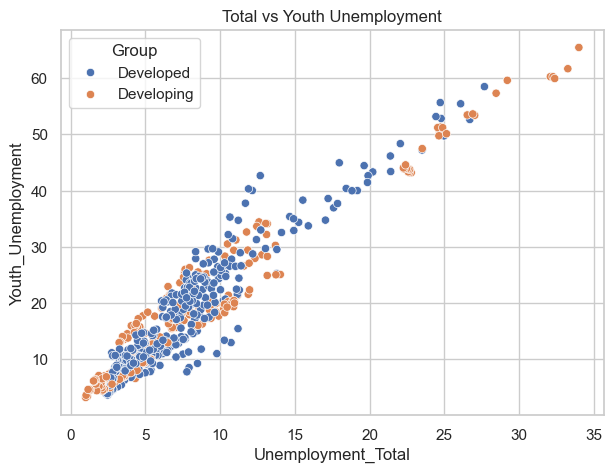

Correlation: 0.95


In [44]:
# Total vs youth unemployment
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Unemployment_Total", y="Youth_Unemployment", hue="Group")
plt.title("Total vs Youth Unemployment")
plt.show()

print("Correlation:", round(df["Unemployment_Total"].corr(df["Youth_Unemployment"]), 2))

**Interpretation:**
Points rise along a straight line for both groups and Correlation is 0.95 (very strong) means,
When total unemployment rises, youth unemployment rises with it.

In [45]:
# Youth ratio by country
ratio = df.groupby("Country")["Youth_Ratio"].mean().sort_values(ascending=False)
print("Average youth ratio:", round(ratio.mean(), 2))
ratio.round(2)

Average youth ratio: 2.43


Country
Indonesia         3.50
Italy             3.16
India             3.15
Vietnam           3.10
Sweden            2.80
Poland            2.78
Philippines       2.71
Egypt             2.68
United Kingdom    2.67
South Korea       2.62
France            2.40
Greece            2.39
China             2.38
Bangladesh        2.25
Spain             2.18
Australia         2.17
Brazil            2.15
United States     2.12
Mexico            1.98
South Africa      1.97
Turkey            1.86
Canada            1.86
Japan             1.77
Germany           1.55
Name: Youth_Ratio, dtype: float64

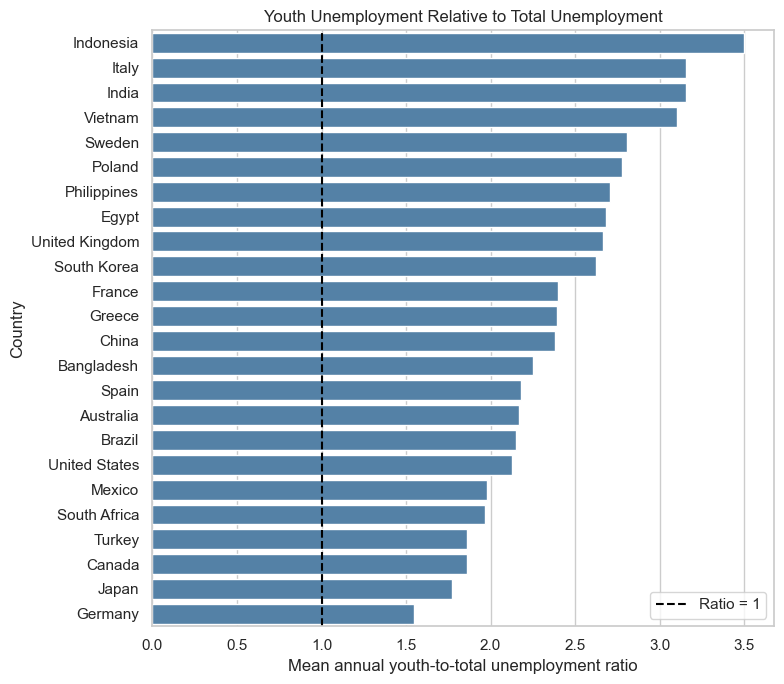

In [46]:
plt.figure(figsize=(8, 7))
sns.barplot(x=ratio.values, y=ratio.index, color="steelblue")
plt.axvline(1, color="black", linestyle="--", label="Ratio = 1")
plt.xlabel("Mean annual youth-to-total unemployment ratio")
plt.ylabel("Country")
plt.title("Youth Unemployment Relative to Total Unemployment")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** 
*  A ratio above 1 means the youth unemployment rate is higher than the total unemployment rate for that observation.
*  The ratio is different for each country. Indonesia, Italy, India and Vietnam have the longest bars, and Germany and Japan have the shortest.
*  On average, the youth unemployment rate is about 2.4 times the total rate, and it is above 1 in all 24 countries.
*  The size of the gap depends on the country, not on whether it is developed or developing

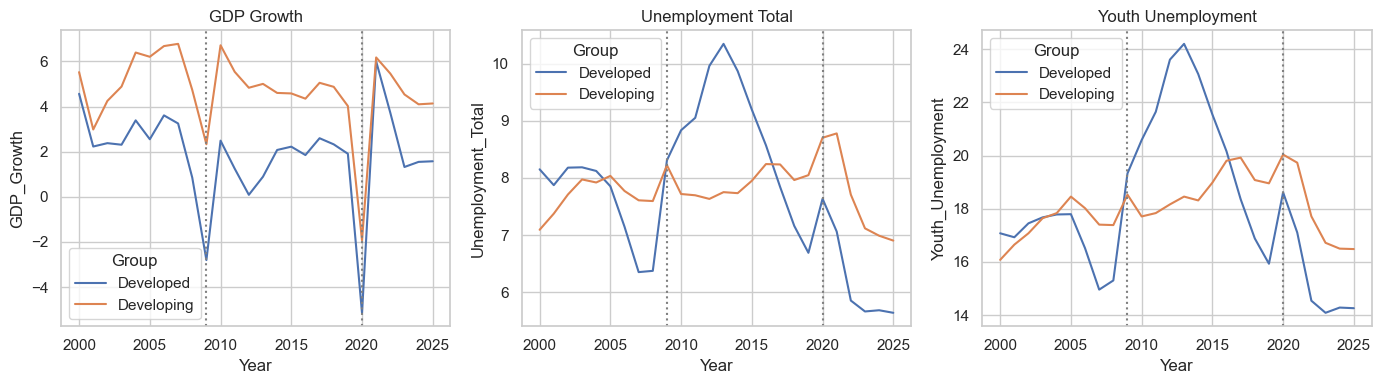

In [47]:
# Average trend for each group
plt.figure(figsize=(14, 4))
for i, col in enumerate(["GDP_Growth", "Unemployment_Total", "Youth_Unemployment"]):
    plt.subplot(1, 3, i + 1)
    sns.lineplot(data=df, x="Year", y=col, hue="Group", errorbar=None)
    plt.axvline(2009, color="grey", linestyle=":")
    plt.axvline(2020, color="grey", linestyle=":")
    plt.title(col.replace("_", " "))
plt.tight_layout()
plt.show()

**Interpretation:** 
* Both crises (2009 and 2020) pushed GDP growth down sharply in both groups, and it recovered quickly the next year.
* The 2008 crisis caused a long rise in unemployment in developed countries, peaking around 2013, while COVID-19 caused only a short spike that fell fast.
* Developing countries grow faster, and their unemployment stays fairly steady.
* Youth unemployment moves in the same pattern as total unemployment, so shocks hit both together.

## 4. Crisis Analysis: 2008–09 Financial Crisis vs COVID-19

This section compares selected annual observations around 2009 and 2020, including GDP growth and year-over-year changes in total and youth unemployment. The years shown provide a focused comparison, not a complete causal evaluation of either crisis.

In [48]:
# Average GDP growth and unemployment change around each crisis, by group
years = [2008, 2009, 2010, 2011, 2019, 2020, 2021, 2022]
crisis = df[df["Year"].isin(years)]

crisis.pivot_table(index="Year", columns="Group",
                   values=["GDP_Growth", "Unemp_Change", "Youth_Change"]).round(2)

GDP_Growth            Unemp_Change            Youth_Change           
Group  Developed Developing    Developed Developing    Developed Developing
Year                                                                       
2008        0.85       4.74         0.02      -0.01         0.34      -0.02
2009       -2.80       2.33         1.94       0.63         4.02       1.14
2010        2.49       6.72         0.53      -0.50         1.25      -0.82
2011        1.25       5.54         0.22      -0.02         1.07       0.13
2019        1.91       4.02        -0.47       0.09        -0.95      -0.12
2020       -5.14      -1.92         0.95       0.66         2.68       1.08
2021        6.00       6.18        -0.57       0.08        -1.51      -0.31
2022        3.73       5.46        -1.21      -1.07        -2.56      -2.02

**Interpretation:** 
* 2008 crisis: the shock appears in 2009. Developed countries' GDP fell to -2.80% and unemployment rose by 1.94 points, while developing countries still grew (2.33%) and unemployment rose by only 0.63 points.
* Unemployment kept rising in developed countries in 2010 and 2011, so the 2008 crisis caused a long job-market problem.
* COVID-19: GDP fell in both groups in 2020 (-5.14% developed, -1.92% developing), but unemployment rose less than in 2009 (0.95 points in developed countries) and was already falling by 2021, so recovery was faster.
* In both crisis years (2009 and 2020), youth unemployment rose by more points than total unemployment in both groups.

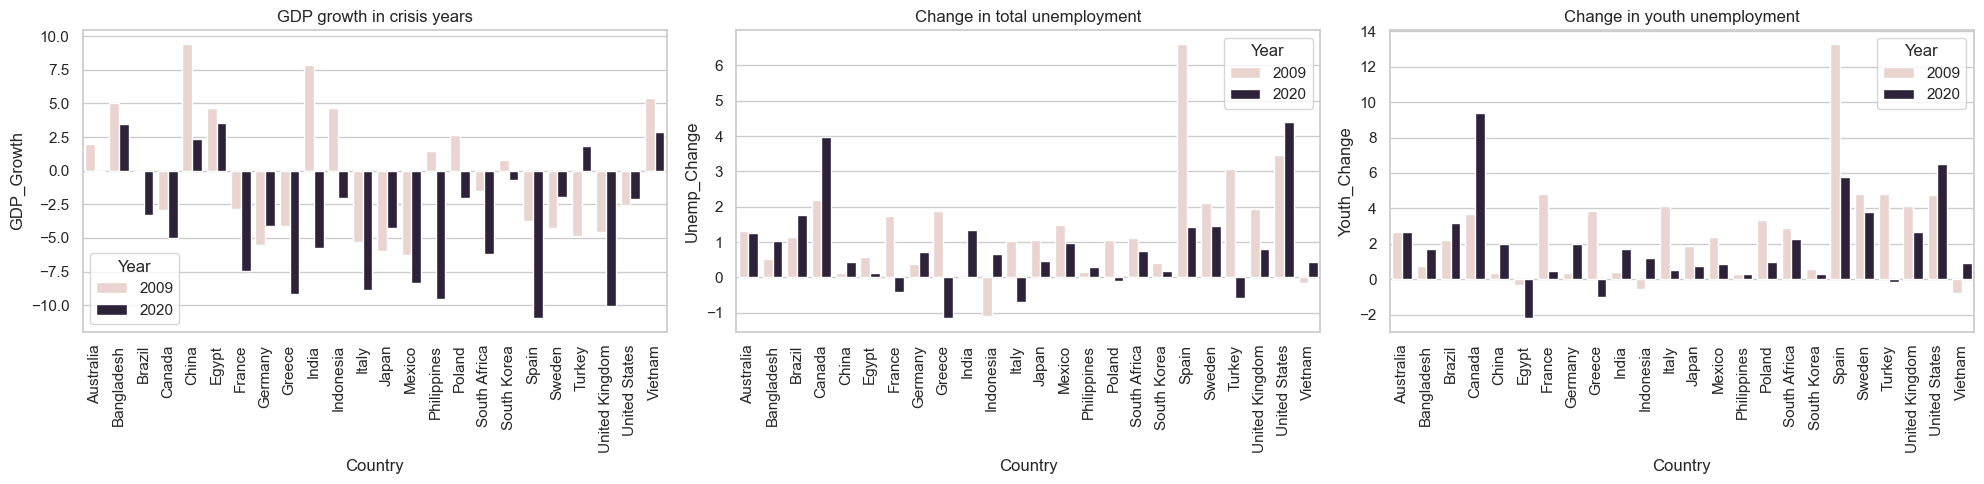

In [49]:
# Each country in the two crisis years
two_years = df[df["Year"].isin([2009, 2020])]

plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
sns.barplot(data=two_years, x="Country", y="GDP_Growth", hue="Year")
plt.xticks(rotation=90)
plt.title("GDP growth in crisis years")

plt.subplot(1, 3, 2)
sns.barplot(data=two_years, x="Country", y="Unemp_Change", hue="Year")
plt.xticks(rotation=90)
plt.title("Change in total unemployment")

plt.subplot(1, 3, 3)
sns.barplot(data=two_years, x="Country", y="Youth_Change", hue="Year")
plt.xticks(rotation=90)
plt.title("Change in youth unemployment")

plt.tight_layout()
plt.show()

**Interpretation:** 
* **Main insight: GDP falls and job losses do not always go together. Countries were hit very differently in both crises, and young people lost jobs the most where unemployment rose.**
* A big GDP fall did not always mean big job losses. Germany in 2009 and the Philippines in 2020 had large GDP falls but little rise in unemployment.
* Job losses were concentrated in a few countries: Spain in 2009, and the US and Canada in 2020. There, youth unemployment rose far more than total unemployment.
* In 2009, China, India, Indonesia, Vietnam and Bangladesh kept growing, while in 2020 only a few countries (China, Bangladesh, Egypt, Vietnam, Turkey) stayed positive.

In [50]:
# Are young people hit harder than the overall workforce in a crisis?
two_years.groupby("Year")[["Unemp_Change", "Youth_Change"]].mean().round(2)

,Unemp_Change,Youth_Change
Year,,
2009,1.34,2.70
2020,0.81,1.95


**Interpretation:** 
* **young people were hit harder than the overall workforce in both crises.**
* In 2009, youth unemployment rose by 2.70 points against 1.34 for total unemployment. In 2020 it rose by 1.95 points against 0.81.

## 5. Relationship Between GDP Growth and Unemployment

The correlation heatmap summarizes pairwise linear relationships between GDP growth, unemployment rates, and year-over-year unemployment changes. Correlations describe association, not causation.

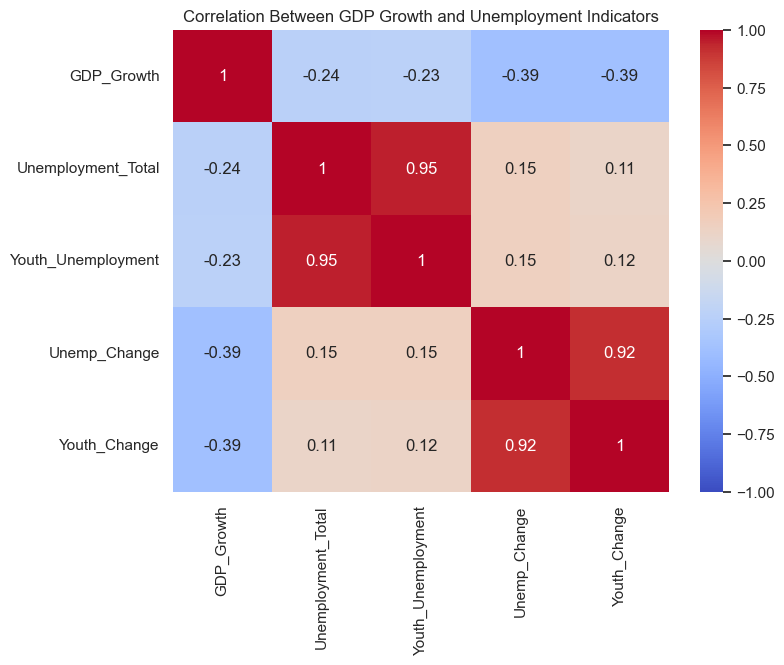

In [51]:

# Correlation heatmap
corr_cols = ["GDP_Growth", "Unemployment_Total",
             "Youth_Unemployment", "Unemp_Change", "Youth_Change"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr().round(2), annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, center=0)
plt.title("Correlation Between GDP Growth and Unemployment Indicators")
plt.show()

**Interpretation:** 
### Interpretation
* **when GDP growth falls, unemployment tends to rise, but the link is only moderate.**
* GDP growth has a moderate negative link with the yearly change in unemployment (-0.39, same for youth and total). Its link with the unemployment level is weaker (-0.24).
* Total and youth unemployment move almost together (0.95), and so do their yearly changes (0.92), so a shock that raises one raises the other.

## 6. Conclusion, Limitations, and Future Scope

### Conclusion

- **Change over time:** GDP growth declined sharply in 2009 and 2020, while unemployment increased during both periods.
- **Youth vs overall:** Average youth unemployment (18.1%) was much higher than total unemployment (7.8%), with a youth ratio of 2.43.
- **Developed vs developing:** Developing countries had higher average GDP growth (4.72% vs 1.89%), while unemployment remained nearly equal at around 7.8%.
- **2008 crisis vs COVID-19:** The 2009 crisis caused a larger rise in unemployment, while the 2020 crisis caused a deeper GDP decline in developed countries.
- **Youth in crises:** Youth unemployment increased more than total unemployment during both crises, showing that young people were more affected.
- **GDP vs unemployment:** GDP growth and unemployment had a moderate negative correlation (-0.39), meaning lower growth was generally associated with higher unemployment.
- **Overall:** Economic crises affected growth and employment differently, with youth unemployment remaining a major concern.

## Limitations
* The analysis focuses mainly on GDP growth and unemployment, excluding other factors such as inflation, education, and government policies that may influence economic trends.
* The results show a relationship, not proof of cause and effect.

## Future Scope
* Include more countries and extend the study period.
* Add other factors like inflation, education and government spending.
* Compare more events, such as the 1997 Asian crisis.